# 1. Setup

In [80]:
!pip -q install librosa soundfile huggingface_hub

In [81]:
!pip -q install librosa soundfile huggingface_hub

import copy
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from collections import Counter
from tqdm.auto import tqdm
from huggingface_hub import list_repo_files, hf_hub_download
from IPython.display import Audio, display

SR = 16000
CLIP_SECONDS = 2
CLIP_LENGTH = SR * CLIP_SECONDS
REPO_ID = "GTSinger/GTSinger"

# 2. Load Audio Data

In [82]:
# Find audio files

files = list_repo_files(
    repo_id=REPO_ID,
    repo_type="dataset"
)

singing_files = [
    f for f in files
    if f.startswith("English/")
    and f.lower().endswith(".wav")
    and "Control_Group" in f
]

speech_files = [
    f for f in files
    if f.startswith("English/")
    and f.lower().endswith(".wav")
    and "Paired_Speech_Group" in f
]

print("Singing files:", len(singing_files))
print("Speech files:", len(speech_files))

assert singing_files, "No singing WAV files found."
assert speech_files, "No speech WAV files found."

Singing files: 2065
Speech files: 2065


# 3. Audio Preprocessing and Mixing
Remove leading and trailing silence using an energy-based method.
Mix spoken speech and singing at controlled Speech-to-Singing Ratios.

In [86]:
def calculate_rms(audio):
    """Calculate root mean square amplitude."""
    return np.sqrt(np.mean(audio**2) + 1e-10)


def mix_audio(speech, singing, ssr_db=0):
    """
    Mix speech and singing at a target SSR.

    Args:
        speech: Spoken speech waveform.
        singing: Singing waveform.
        ssr_db: Speech-to-Singing Ratio in dB.

    Returns:
        mixture: Combined audio.
        speech_component: Scaled speech.
        singing_component: Scaled singing.
    """

    # Match lengths
    length = min(len(speech), len(singing))

    speech = speech[:length].astype(np.float32)
    singing = singing[:length].astype(np.float32)

    # Normalize RMS
    speech = speech / calculate_rms(speech)
    singing = singing / calculate_rms(singing)

    # Convert dB to amplitude ratio
    speech_gain = 10 ** (ssr_db / 20)

    # Mix signals
    speech_scaled = speech_gain * speech
    mixture = speech_scaled + singing

    # Prevent clipping
    peak = np.max(np.abs(mixture))
    scale = max(peak, 1.0)

    mixture = mixture / scale
    speech_component = speech_scaled / scale
    singing_component = singing / scale

    return mixture, speech_component, singing_component

# 4. Dataset Generation
Prepare multiple speech and singing recordings for training, validation, and testing.

In [87]:
def get_singer_id(filepath):
    return filepath.split("/")[1]

singing_singers = Counter(
    get_singer_id(f) for f in singing_files
)

speech_singers = Counter(
    get_singer_id(f) for f in speech_files
)

print("=== Singing files by singer ===")
for singer, count in sorted(singing_singers.items()):
    print(f"{singer}: {count}")

print("\n=== Speech files by singer ===")
for singer, count in sorted(speech_singers.items()):
    print(f"{singer}: {count}")

=== Singing files by singer ===
EN-Alto-1: 537
EN-Alto-2: 741
EN-Tenor-1: 787

=== Speech files by singer ===
EN-Alto-1: 537
EN-Alto-2: 741
EN-Tenor-1: 787


In [88]:
available_singers = sorted(
    set(singing_singers) & set(speech_singers)
)

print("Available singers:", available_singers)
print("Number of singers:", len(available_singers))

Available singers: ['EN-Alto-1', 'EN-Alto-2', 'EN-Tenor-1']
Number of singers: 3


In [89]:
# Split singers into train, validation, and test sets

train_singers = ["EN-Alto-2"]
val_singers = ["EN-Alto-1"]
test_singers = ["EN-Tenor-1"]

print("Train singers:", train_singers)
print("Validation singers:", val_singers)
print("Test singers:", test_singers)

Train singers: ['EN-Alto-2']
Validation singers: ['EN-Alto-1']
Test singers: ['EN-Tenor-1']


In [90]:
# Select files belonging to specific singers

def select_files(file_list, singer_ids):
    return [
        f for f in file_list
        if get_singer_id(f) in singer_ids
    ]


splits = {}

for name, singers in {
    "train": train_singers,
    "val": val_singers,
    "test": test_singers,
}.items():

    splits[name] = {
        "speech": select_files(speech_files, singers),
        "singing": select_files(singing_files, singers),
    }

    print(f"\n{name.upper()}")
    print("Speech:", len(splits[name]["speech"]))
    print("Singing:", len(splits[name]["singing"]))


TRAIN
Speech: 741
Singing: 741

VAL
Speech: 537
Singing: 537

TEST
Speech: 787
Singing: 787


In [92]:
random.seed(42)

# Start with a small subset
NUM_FILES = 100

train_speech_files = random.sample(
    splits["train"]["speech"],
    NUM_FILES
)

train_singing_files = random.sample(
    splits["train"]["singing"],
    NUM_FILES
)

print("Selected speech files:", len(train_speech_files))
print("Selected singing files:", len(train_singing_files))

Selected speech files: 100
Selected singing files: 100


In [93]:
def load_audio_files(file_paths, sr=16000):
    audio_list = []

    for filepath in tqdm(file_paths):

        local_path = hf_hub_download(
            repo_id=REPO_ID,
            filename=filepath,
            repo_type="dataset"
        )

        audio, _ = librosa.load(
            local_path,
            sr=sr
        )

        if len(audio) > 0:
            audio_list.append(audio)

    return audio_list

In [94]:
train_speech_audio = load_audio_files(
    train_speech_files,
    sr=SR
)

train_singing_audio = load_audio_files(
    train_singing_files,
    sr=SR
)

print("Speech recordings:", len(train_speech_audio))
print("Singing recordings:", len(train_singing_audio))

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

Speech recordings: 100
Singing recordings: 100


# 5. Feature Extraction

In [100]:
N_MELS = 64
N_FFT = 1024
HOP_LENGTH = 160

def extract_logmel(audio):
    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=SR,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS,
        center=True
    )

    logmel = librosa.power_to_db(
        mel,
        ref=1.0
    )

    return logmel.astype(np.float32)

# 6. Training Dataset Preparation

Create datasets for two training conditions:

- Model A: Speech and Singing without overlap
- Model B: Speech and Singing with overlap

In [102]:
def extract_active_clip(audio, clip_length=CLIP_LENGTH, min_rms=0.005):
    """
    Extract a fixed-length clip with sufficient audio energy.
    """

    if len(audio) < clip_length:
        audio = np.pad(
            audio,
            (0, clip_length - len(audio))
        )

    for _ in range(30):
        max_start = len(audio) - clip_length

        start = np.random.randint(0, max_start + 1)

        clip = audio[start:start + clip_length]

        if calculate_rms(clip) >= min_rms:
            return clip.astype(np.float32)

    # Reject files without a sufficiently active clip
    raise ValueError("No active clip found")

In [103]:
def normalize_audio(audio, target_rms=0.05):
    """
    Normalize the overall RMS while preventing clipping.
    """

    current_rms = calculate_rms(audio)

    audio = audio * (target_rms / current_rms)

    # Prevent clipping
    peak = np.max(np.abs(audio))

    if peak > 1.0:
        audio = audio / peak

    return audio.astype(np.float32)

In [104]:
def create_base_clips(
    speech_audio,
    singing_audio,
    num_samples=1200,
    seed=42
):
    """
    Create a shared pool of speech and singing clips
    for controlled A/B training experiments.
    """

    rng = random.Random(seed)

    num_positive = num_samples // 2
    num_negative = num_samples // 2

    speech_clips = []
    singing_clips = []

    # Generate speech clips
    while len(speech_clips) < num_positive:

        audio = rng.choice(speech_audio)

        try:
            clip = extract_active_clip(audio)
            speech_clips.append(clip)
        except ValueError:
            continue

    # Generate singing clips
    while len(singing_clips) < num_negative:

        audio = rng.choice(singing_audio)

        try:
            clip = extract_active_clip(audio)
            singing_clips.append(clip)
        except ValueError:
            continue

    return (
        np.stack(speech_clips),
        np.stack(singing_clips)
    )

In [105]:
random.seed(42)
np.random.seed(42)

base_speech, base_singing = create_base_clips(
    train_speech_audio,
    train_singing_audio,
    num_samples=1200,
    seed=42
)

print("Speech:", base_speech.shape)
print("Singing:", base_singing.shape)

Speech: (600, 32000)
Singing: (600, 32000)


In [106]:
def create_controlled_datasets(
    speech_clips,
    singing_clips,
    seed=42
):
    """
    Create controlled A/B datasets.

    Model A:
        50% speech
        50% singing

    Model B:
        25% speech
        50% singing
        25% overlap

    Both models share the same underlying
    speech and singing clips.
    """

    rng = np.random.default_rng(seed)

    num_positive = len(speech_clips)
    num_negative = len(singing_clips)

    assert num_positive == num_negative
    assert num_positive % 2 == 0

    # Randomly select half of speech clips for overlap
    overlap_indices = set(
        rng.choice(
            num_positive,
            size=num_positive // 2,
            replace=False
        ).tolist()
    )

    # Model A
    X_A = []
    y_A = []
    types_A = []

    # Model B
    X_B = []
    y_B = []
    types_B = []

    # Shared speech clips
    for i, speech in enumerate(speech_clips):

        # Model A: speech only
        X_A.append(normalize_audio(speech))
        y_A.append(1)
        types_A.append("speech")

        # Model B: speech or overlap
        if i in overlap_indices:

            singing = singing_clips[
                rng.integers(num_negative)
            ]

            ssr = rng.choice([-10, 0, 10])

            audio, _, _ = mix_audio(
                speech,
                singing,
                ssr_db=float(ssr)
            )

            X_B.append(normalize_audio(audio))
            types_B.append("overlap")

        else:
            X_B.append(normalize_audio(speech))
            types_B.append("speech")

        y_B.append(1)

    # Shared singing-only clips
    for singing in singing_clips:

        audio = normalize_audio(singing)

        X_A.append(audio.copy())
        X_B.append(audio.copy())

        y_A.append(0)
        y_B.append(0)

        types_A.append("singing")
        types_B.append("singing")

    # Use the same shuffle for both datasets
    indices = rng.permutation(len(X_A))

    X_A = np.stack(X_A)[indices]
    X_B = np.stack(X_B)[indices]

    y_A = np.array(y_A, dtype=np.int64)[indices]
    y_B = np.array(y_B, dtype=np.int64)[indices]

    types_A = np.array(types_A)[indices]
    types_B = np.array(types_B)[indices]

    return X_A, y_A, types_A, X_B, y_B, types_B

In [107]:
X_A, y_A, types_A, X_B, y_B, types_B = (
    create_controlled_datasets(
        base_speech,
        base_singing,
        seed=42
    )
)

print("Model A:", X_A.shape)
print("Model B:", X_B.shape)

print("\nModel A distribution:")
print(Counter(types_A))

print("\nModel B distribution:")
print(Counter(types_B))

Model A: (1200, 32000)
Model B: (1200, 32000)

Model A distribution:
Counter({np.str_('speech'): 600, np.str_('singing'): 600})

Model B distribution:
Counter({np.str_('singing'): 600, np.str_('speech'): 300, np.str_('overlap'): 300})


# 7. Validation and Test Data

Prepare held-out speech and singing recordings for evaluating Model A and Model B.

In [108]:
random.seed(123)

NUM_EVAL_FILES = 20

val_speech_files = random.sample(
    splits["val"]["speech"],
    NUM_EVAL_FILES
)

val_singing_files = random.sample(
    splits["val"]["singing"],
    NUM_EVAL_FILES
)

test_speech_files = random.sample(
    splits["test"]["speech"],
    NUM_EVAL_FILES
)

test_singing_files = random.sample(
    splits["test"]["singing"],
    NUM_EVAL_FILES
)

In [109]:
val_speech_audio = load_audio_files(
    val_speech_files,
    sr=SR
)

val_singing_audio = load_audio_files(
    val_singing_files,
    sr=SR
)

test_speech_audio = load_audio_files(
    test_speech_files,
    sr=SR
)

test_singing_audio = load_audio_files(
    test_singing_files,
    sr=SR
)

print("Validation speech:", len(val_speech_audio))
print("Validation singing:", len(val_singing_audio))
print("Test speech:", len(test_speech_audio))
print("Test singing:", len(test_singing_audio))

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

Validation speech: 20
Validation singing: 20
Test speech: 20
Test singing: 20


In [110]:
def generate_eval_dataset(
    speech_audio,
    singing_audio,
    samples_per_condition=50,
    seed=42
):
    """
    Generate evaluation data under five conditions:
    speech, singing, overlap_-10, overlap_0, overlap_10.
    """

    rng = np.random.default_rng(seed)

    X = []
    y = []
    conditions = []

    eval_conditions = [
        ("speech", None),
        ("singing", None),
        ("overlap_-10", -10),
        ("overlap_0", 0),
        ("overlap_10", 10),
    ]

    for condition, ssr in eval_conditions:
        for _ in range(samples_per_condition):

            # Use reproducible random sampling
            speech_idx = rng.integers(len(speech_audio))
            singing_idx = rng.integers(len(singing_audio))

            speech = extract_active_clip(
                speech_audio[speech_idx]
            )

            singing = extract_active_clip(
                singing_audio[singing_idx]
            )

            if condition == "speech":
                audio = speech
                label = 1

            elif condition == "singing":
                audio = singing
                label = 0

            else:
                audio, _, _ = mix_audio(
                    speech,
                    singing,
                    ssr_db=ssr
                )
                label = 1

            audio = normalize_audio(audio)

            X.append(audio)
            y.append(label)
            conditions.append(condition)

    return (
        np.stack(X),
        np.array(y, dtype=np.int64),
        np.array(conditions)
    )

In [111]:
np.random.seed(100)

X_val, y_val, conditions_val = generate_eval_dataset(
    val_speech_audio,
    val_singing_audio,
    samples_per_condition=50,
    seed=100
)

print("Validation:", X_val.shape, y_val.shape)
print(Counter(conditions_val))

Validation: (250, 32000) (250,)
Counter({np.str_('speech'): 50, np.str_('singing'): 50, np.str_('overlap_-10'): 50, np.str_('overlap_0'): 50, np.str_('overlap_10'): 50})


In [112]:
np.random.seed(200)

X_test, y_test, conditions_test = generate_eval_dataset(
    test_speech_audio,
    test_singing_audio,
    samples_per_condition=50,
    seed=200
)

print("Test:", X_test.shape, y_test.shape)
print(Counter(conditions_test))

Test: (250, 32000) (250,)
Counter({np.str_('speech'): 50, np.str_('singing'): 50, np.str_('overlap_-10'): 50, np.str_('overlap_0'): 50, np.str_('overlap_10'): 50})


In [113]:
X_val_features = np.stack([
    extract_logmel(audio)
    for audio in tqdm(X_val)
])

X_test_features = np.stack([
    extract_logmel(audio)
    for audio in tqdm(X_test)
])

print("Validation features:", X_val_features.shape)
print("Test features:", X_test_features.shape)

  0%|          | 0/250 [00:00<?, ?it/s]

  0%|          | 0/250 [00:00<?, ?it/s]

Validation features: (250, 64, 201)
Test features: (250, 64, 201)


# 8. CNN Model

Implement a CNN-based spoken-speech classifier using PyTorch.

In [114]:
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

Device: cpu


In [115]:
class SpeechCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Linear(64, 1)

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, start_dim=1)
        x = self.classifier(x)

        return x.squeeze(1)

In [117]:
X_A_features = np.stack([
    extract_logmel(audio)
    for audio in tqdm(X_A)
])

X_B_features = np.stack([
    extract_logmel(audio)
    for audio in tqdm(X_B)
])

print("Model A:", X_A_features.shape)
print("Model B:", X_B_features.shape)

  0%|          | 0/1200 [00:00<?, ?it/s]

  0%|          | 0/1200 [00:00<?, ?it/s]

Model A: (1200, 64, 201)
Model B: (1200, 64, 201)


In [118]:
def make_loader(X, y, batch_size=32, shuffle=False):

    X_tensor = torch.tensor(
        X[:, None, :, :],
        dtype=torch.float32
    )

    y_tensor = torch.tensor(
        y,
        dtype=torch.float32
    )

    dataset = TensorDataset(X_tensor, y_tensor)

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle
    )

In [119]:
train_loader_A = make_loader(
    X_A_features, y_A,
    batch_size=32,
    shuffle=True
)

train_loader_B = make_loader(
    X_B_features, y_B,
    batch_size=32,
    shuffle=True
)

val_loader = make_loader(
    X_val_features, y_val,
    batch_size=32
)

print("Model A batches:", len(train_loader_A))
print("Model B batches:", len(train_loader_B))
print("Validation batches:", len(val_loader))

Model A batches: 38
Model B batches: 38
Validation batches: 8


In [120]:
def train_model(model, train_loader, val_loader, epochs=15):

    model = model.to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001
    )

    criterion = nn.BCEWithLogitsLoss()

    history = {
        "train_loss": [],
        "val_loss": []
    }

    best_val_loss = float("inf")
    best_state = None

    for epoch in range(epochs):

        # Training
        model.train()
        total_train_loss = 0

        for X_batch, y_batch in train_loader:

            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)

            optimizer.zero_grad()

            logits = model(X_batch)

            loss = criterion(logits, y_batch)

            loss.backward()
            optimizer.step()

            total_train_loss += (
                loss.item() * len(X_batch)
            )

        avg_train_loss = (
            total_train_loss / len(train_loader.dataset)
        )

        # Validation
        model.eval()
        total_val_loss = 0

        with torch.no_grad():

            for X_batch, y_batch in val_loader:

                X_batch = X_batch.to(DEVICE)
                y_batch = y_batch.to(DEVICE)

                logits = model(X_batch)

                loss = criterion(logits, y_batch)

                total_val_loss += (
                    loss.item() * len(X_batch)
                )

        avg_val_loss = (
            total_val_loss / len(val_loader.dataset)
        )

        history["train_loss"].append(avg_train_loss)
        history["val_loss"].append(avg_val_loss)

        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            best_state = copy.deepcopy(model.state_dict())

        print(
            f"Epoch {epoch+1:02d} | "
            f"Train Loss: {avg_train_loss:.4f} | "
            f"Val Loss: {avg_val_loss:.4f}"
        )

    model.load_state_dict(best_state)

    return model, history

In [121]:
torch.manual_seed(42)

initial_model = SpeechCNN()
initial_state = copy.deepcopy(initial_model.state_dict())

model_A = SpeechCNN()
model_A.load_state_dict(initial_state)

model_B = SpeechCNN()
model_B.load_state_dict(initial_state)

<All keys matched successfully>

In [122]:
print("Training Model A")

model_A, history_A = train_model(
    model_A,
    train_loader_A,
    val_loader,
    epochs=15
)

print("\nTraining Model B")

model_B, history_B = train_model(
    model_B,
    train_loader_B,
    val_loader,
    epochs=15
)

Training Model A
Epoch 01 | Train Loss: 0.4012 | Val Loss: 0.6205
Epoch 02 | Train Loss: 0.2322 | Val Loss: 1.1294
Epoch 03 | Train Loss: 0.1604 | Val Loss: 0.7307
Epoch 04 | Train Loss: 0.1350 | Val Loss: 3.7692
Epoch 05 | Train Loss: 0.1223 | Val Loss: 1.0190
Epoch 06 | Train Loss: 0.0888 | Val Loss: 2.7299
Epoch 07 | Train Loss: 0.0828 | Val Loss: 0.6540
Epoch 08 | Train Loss: 0.0750 | Val Loss: 4.9046
Epoch 09 | Train Loss: 0.0798 | Val Loss: 0.8202
Epoch 10 | Train Loss: 0.0593 | Val Loss: 3.6976
Epoch 11 | Train Loss: 0.0685 | Val Loss: 4.0712
Epoch 12 | Train Loss: 0.0713 | Val Loss: 3.5213
Epoch 13 | Train Loss: 0.0591 | Val Loss: 2.9368
Epoch 14 | Train Loss: 0.0439 | Val Loss: 2.5853
Epoch 15 | Train Loss: 0.0432 | Val Loss: 1.3517

Training Model B
Epoch 01 | Train Loss: 0.4881 | Val Loss: 0.3640
Epoch 02 | Train Loss: 0.3695 | Val Loss: 0.5477
Epoch 03 | Train Loss: 0.3154 | Val Loss: 0.2768
Epoch 04 | Train Loss: 0.2714 | Val Loss: 0.2301
Epoch 05 | Train Loss: 0.2444 | Va

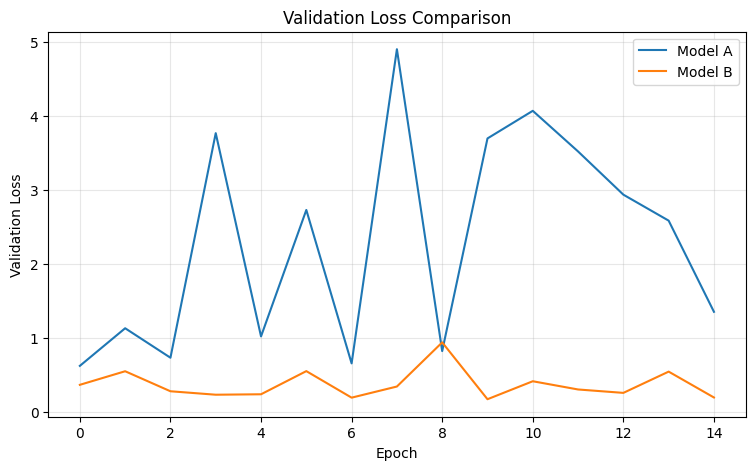

In [123]:
plt.figure(figsize=(9, 5))

plt.plot(history_A["val_loss"], label="Model A")
plt.plot(history_B["val_loss"], label="Model B")

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss Comparison")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

# 9. Model Evaluation

Evaluate speech detection performance on held-out singers.

In [124]:
test_loader = make_loader(
    X_test_features,
    y_test,
    batch_size=32,
    shuffle=False
)

def predict_probabilities(model, loader):
    model.eval()

    probabilities = []

    with torch.no_grad():
        for X_batch, _ in loader:
            X_batch = X_batch.to(DEVICE)

            logits = model(X_batch)
            probs = torch.sigmoid(logits)

            probabilities.extend(
                probs.cpu().numpy()
            )

    return np.array(probabilities)

Model A predictions: (250,)
Model B predictions: (250,)


In [128]:
def select_threshold(probs, conditions, max_fpr=0.10):

    thresholds = np.linspace(0, 1, 1001)

    singing_mask = conditions == "singing"
    overlap_mask = np.char.startswith(
        conditions.astype(str), "overlap"
    )

    best_threshold = None
    best_recall = -1

    for threshold in thresholds:

        pred = probs >= threshold

        fpr = pred[singing_mask].mean()
        recall = pred[overlap_mask].mean()

        if fpr <= max_fpr and recall > best_recall:
            best_threshold = threshold
            best_recall = recall

    return best_threshold, best_recall

Model A: threshold=0.706, recall=0.240
Model B: threshold=0.829, recall=0.913


In [129]:
def evaluate_at_threshold(probs, conditions, threshold):

    pred = probs >= threshold

    singing_mask = conditions == "singing"
    overlap_mask = np.char.startswith(
        conditions.astype(str), "overlap"
    )

    return {
        "Overlap Recall": pred[overlap_mask].mean(),
        "Singing FPR": pred[singing_mask].mean()
    }

Model A: {'Overlap Recall': np.float64(0.5933333333333334), 'Singing FPR': np.float64(0.0)}
Model B: {'Overlap Recall': np.float64(0.96), 'Singing FPR': np.float64(0.0)}


In [130]:
probs_val_A = predict_probabilities(model_A, val_loader)
probs_val_B = predict_probabilities(model_B, val_loader)


threshold_A, recall_val_A = select_threshold(
    probs_val_A,
    conditions_val
)

threshold_B, recall_val_B = select_threshold(
    probs_val_B,
    conditions_val
)

print(f"Model A threshold: {threshold_A:.3f}")
print(f"Model B threshold: {threshold_B:.3f}")


probs_A = predict_probabilities(model_A, test_loader)
probs_B = predict_probabilities(model_B, test_loader)


results_A = evaluate_at_threshold(
    probs_A,
    conditions_test,
    threshold_A
)

results_B = evaluate_at_threshold(
    probs_B,
    conditions_test,
    threshold_B
)

print("\nModel A:", results_A)
print("Model B:", results_B)

Threshold A: 0.706
Threshold B: 0.8290000000000001


# 10. Label Quality Check

In [132]:
rng = np.random.default_rng(42)

CONDITIONS = [
    "speech",
    "singing",
    "overlap_-10",
    "overlap_0",
    "overlap_10"
]

selected_indices = {}

for condition in CONDITIONS:

    indices = np.where(
        conditions_test == condition
    )[0]

    selected_indices[condition] = rng.choice(
        indices,
        size=5,
        replace=False
    )

    print(condition, selected_indices[condition])

speech [36 21 31  4 49]
singing [96 54 74 88 86]
overlap_-10 [124 138 121 118 109]
overlap_0 [175 161 172 171 187]
overlap_10 [208 239 238 213 230]


In [133]:
for condition in CONDITIONS:

    print(f"\n===== {condition} =====")

    for idx in selected_indices[condition]:

        print(f"Sample {idx} | Label: {y_test[idx]}")

        display(
            Audio(
                X_test[idx],
                rate=SR,
                normalize=False
            )
        )


===== speech =====
Sample 36 | Label: 1


Sample 21 | Label: 1


Sample 31 | Label: 1


Sample 4 | Label: 1


Sample 49 | Label: 1


...


===== overlap_10 =====
Sample 208 | Label: 1


Sample 239 | Label: 1


Sample 238 | Label: 1


Sample 213 | Label: 1


Sample 230 | Label: 1


# 11. Repeated Training

Evaluate the stability of A/B training results across multiple random seeds.

In [134]:
SEEDS = [42, 123, 456]

all_results = []

for seed in SEEDS:

    print(f"\n========== SEED {seed} ==========")

    # Set random seeds
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # Shared initialization for A and B
    initial_model = SpeechCNN()
    initial_state = copy.deepcopy(initial_model.state_dict())

    model_A_repeat = SpeechCNN()
    model_A_repeat.load_state_dict(initial_state)

    model_B_repeat = SpeechCNN()
    model_B_repeat.load_state_dict(initial_state)

    # Train both models
    model_A_repeat, _ = train_model(
        model_A_repeat,
        train_loader_A,
        val_loader,
        epochs=15
    )

    model_B_repeat, _ = train_model(
        model_B_repeat,
        train_loader_B,
        val_loader,
        epochs=15
    )

    for name, model in [
        ("A", model_A_repeat),
        ("B", model_B_repeat)
    ]:

        # Validation predictions
        val_probs = predict_probabilities(
            model, val_loader
        )

        threshold, _ = select_threshold(
            val_probs,
            conditions_val
        )

        # Test predictions
        test_probs = predict_probabilities(
            model, test_loader
        )

        metrics = evaluate_at_threshold(
            test_probs,
            conditions_test,
            threshold
        )

        all_results.append({
            "Seed": seed,
            "Model": name,
            "Threshold": threshold,
            "Overlap Recall": metrics["Overlap Recall"],
            "Singing FPR": metrics["Singing FPR"]
        })

results_df = pd.DataFrame(all_results)

display(results_df)


========== SEED 42 ==========
Epoch 01 | Train Loss: 0.4012 | Val Loss: 0.6205
Epoch 02 | Train Loss: 0.2322 | Val Loss: 1.1294
Epoch 03 | Train Loss: 0.1604 | Val Loss: 0.7307
Epoch 04 | Train Loss: 0.1350 | Val Loss: 3.7692
Epoch 05 | Train Loss: 0.1223 | Val Loss: 1.0190
Epoch 06 | Train Loss: 0.0888 | Val Loss: 2.7299
Epoch 07 | Train Loss: 0.0828 | Val Loss: 0.6540
Epoch 08 | Train Loss: 0.0750 | Val Loss: 4.9046
Epoch 09 | Train Loss: 0.0798 | Val Loss: 0.8202
Epoch 10 | Train Loss: 0.0593 | Val Loss: 3.6976
Epoch 11 | Train Loss: 0.0685 | Val Loss: 4.0712
Epoch 12 | Train Loss: 0.0713 | Val Loss: 3.5213
Epoch 13 | Train Loss: 0.0591 | Val Loss: 2.9368
Epoch 14 | Train Loss: 0.0439 | Val Loss: 2.5853
Epoch 15 | Train Loss: 0.0432 | Val Loss: 1.3517
Epoch 01 | Train Loss: 0.4881 | Val Loss: 0.3640
Epoch 02 | Train Loss: 0.3695 | Val Loss: 0.5477
Epoch 03 | Train Loss: 0.3154 | Val Loss: 0.2768
Epoch 04 | Train Loss: 0.2714 | Val Loss: 0.2301
Epoch 05 | Train Loss: 0.2444 | Val Lo

,Seed,Model,Threshold,Overlap Recall,Singing FPR
0,42,A,0.706,0.593333,0.0
1,42,B,0.829,0.960000,0.0
2,123,A,0.637,0.686667,0.0
3,123,B,0.710,0.980000,0.0
4,456,A,0.999,0.133333,0.0
5,456,B,0.916,0.926667,0.0


In [135]:
summary = (
    results_df
    .groupby("Model")[
        ["Overlap Recall", "Singing FPR"]
    ]
    .agg(["mean", "std"])
)

display(summary)

Overlap Recall           Singing FPR     
                mean       std        mean  std
Model                                          
A           0.471111  0.296223         0.0  0.0
B           0.955556  0.026943         0.0  0.0

# 12. Results and SSR Analysis

In [136]:
def recall_by_ssr(probs, conditions, threshold):
    results = []

    for ssr in [-10, 0, 10]:
        condition = f"overlap_{ssr}"
        mask = conditions == condition

        predictions = probs[mask] >= threshold
        recall = predictions.mean()

        results.append({
            "SSR (dB)": ssr,
            "Recall": recall
        })

    return pd.DataFrame(results)

results_A_ssr = recall_by_ssr(
    probs_A,
    conditions_test,
    threshold_A
)

results_B_ssr = recall_by_ssr(
    probs_B,
    conditions_test,
    threshold_B
)

comparison_df = results_A_ssr.rename(
    columns={"Recall": "Model A"}
).merge(
    results_B_ssr.rename(
        columns={"Recall": "Model B"}
    ),
    on="SSR (dB)"
)

display(comparison_df)

,SSR (dB),Model A,Model B
0,-10,0.14,0.90
1,0,0.70,0.98
2,10,0.94,1.00


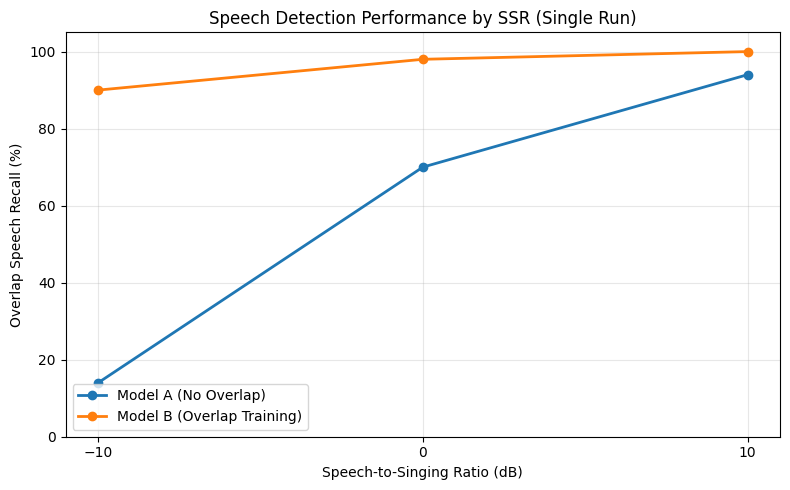

In [137]:
plt.figure(figsize=(8, 5))

plt.plot(
    comparison_df["SSR (dB)"],
    comparison_df["Model A"] * 100,
    marker="o",
    linewidth=2,
    label="Model A (No Overlap)"
)

plt.plot(
    comparison_df["SSR (dB)"],
    comparison_df["Model B"] * 100,
    marker="o",
    linewidth=2,
    label="Model B (Overlap Training)"
)

plt.xlabel("Speech-to-Singing Ratio (dB)")
plt.ylabel("Overlap Speech Recall (%)")
plt.title("Speech Detection Performance by SSR (Single Run)")

plt.xticks([-10, 0, 10])
plt.ylim(0, 105)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    "ssr_recall_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()